# 3. Dataset Exploration & Conversion

What's actually in the three raw datasets, and what the adapters in
`carla_gym/core/dataset_adapters.py` do to turn them into something
`TraceTrafficGenerator` can use. This also demonstrates the topology-aware
node placement fix: putting the busiest real-world host on the
best-connected simulated node instead of wherever a hash happened to
land it.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.core.network import NetworkModel
from carla_gym.core.dataset_adapters import (
    convert_cs448b, convert_packet_capture, _topology_degree_order,
)

plt.rcParams["figure.dpi"] = 100

## Dataset 1: `cs448b_ipasn.csv` -- daily local-host -> remote-ASN flow counts

Stanford's CS448B dataset: one row per (day, local host 0-9, remote ASN),
with a flow count for that day. No per-packet timing -- it's already
daily-aggregated, which is why the adapter uses the day index as `step`.

In [2]:
raw_cs448b = pd.read_csv("data/cs448b_ipasn.csv")
print(f"{len(raw_cs448b)} rows, {raw_cs448b['date'].nunique()} days, "
      f"{raw_cs448b['l_ipn'].nunique()} local hosts, {raw_cs448b['r_asn'].nunique()} remote ASNs")
raw_cs448b.head()

20803 rows, 92 days, 10 local hosts, 2005 remote ASNs


,date,l_ipn,r_asn,f
0,2006-07-01,0,701,1
1,2006-07-01,0,714,1
2,2006-07-01,0,1239,1
3,2006-07-01,0,1680,1
4,2006-07-01,0,2514,1


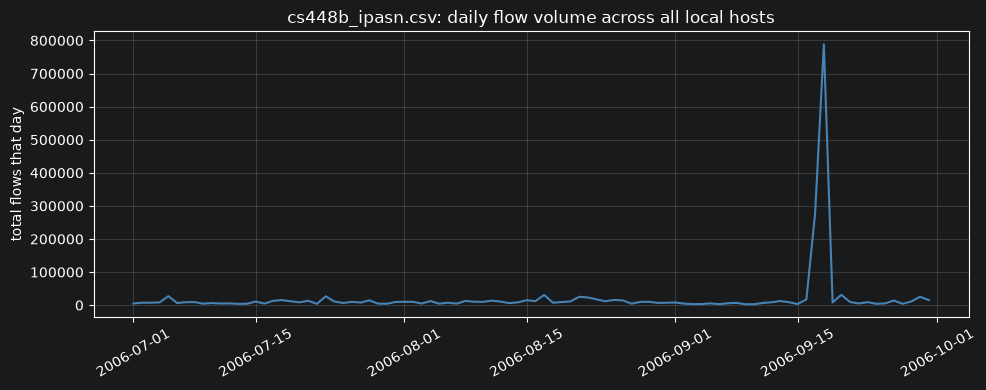

Note the spikes -- this dataset is used in anomaly-detection coursework
precisely because a handful of days have unusually heavy flow counts.


In [3]:
daily_flows = raw_cs448b.groupby("date")["f"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pd.to_datetime(daily_flows.index), daily_flows.values, color="steelblue")
ax.set_ylabel("total flows that day")
ax.set_title("cs448b_ipasn.csv: daily flow volume across all local hosts")
ax.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print("Note the spikes -- this dataset is used in anomaly-detection coursework")
print("precisely because a handful of days have unusually heavy flow counts.")

## Dataset 2 & 3: `output1.csv` and `Midterm_53_group.csv`

These are **the same ~21-minute packet capture**, exported two different
ways: `output1.csv` is the numeric/programmatic export, `Midterm_53_group.csv`
is Wireshark's human-readable text export (which also includes non-IP rows
like MAC-vendor strings and `"Broadcast"` that the adapter drops).

394136 rows, 393502 with a routable src/dst IP
337 unique source IPs, 303 unique destination IPs
capture spans 1257 seconds


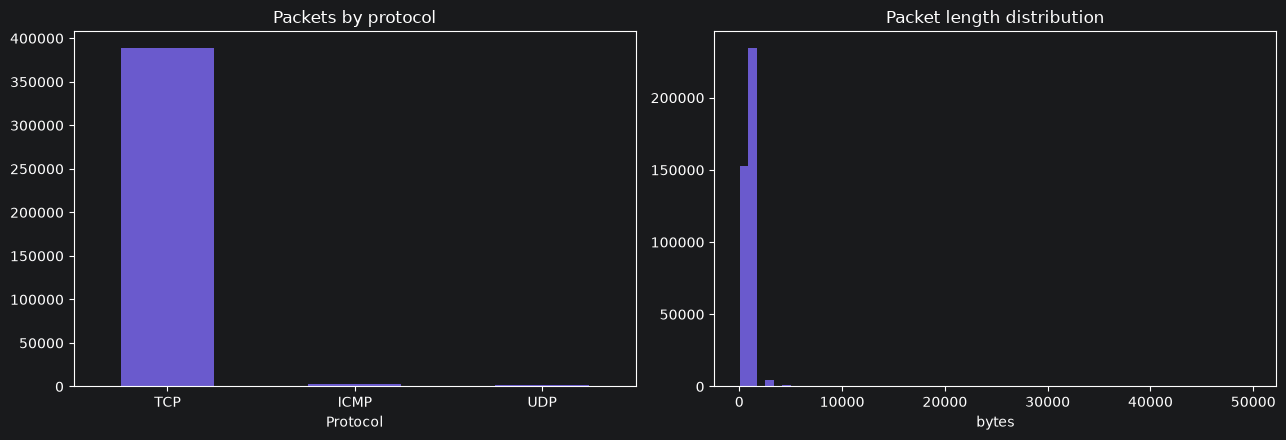

In [4]:
raw_pcap = pd.read_csv("data/output1.csv")
valid = raw_pcap.dropna(subset=["Source IP", "Destination IP"])
print(f"{len(raw_pcap)} rows, {len(valid)} with a routable src/dst IP")
print(f"{valid['Source IP'].nunique()} unique source IPs, "
      f"{valid['Destination IP'].nunique()} unique destination IPs")
print(f"capture spans {raw_pcap['Timestamp'].max() - raw_pcap['Timestamp'].min():.0f} seconds")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
valid["Protocol"].map({6: "TCP", 17: "UDP", 1: "ICMP"}).fillna("other").value_counts().plot(
    kind="bar", ax=axes[0], color="slateblue")
axes[0].set_title("Packets by protocol")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(valid["Length"], bins=60, color="slateblue")
axes[1].set_title("Packet length distribution")
axes[1].set_xlabel("bytes")
plt.tight_layout()
plt.show()

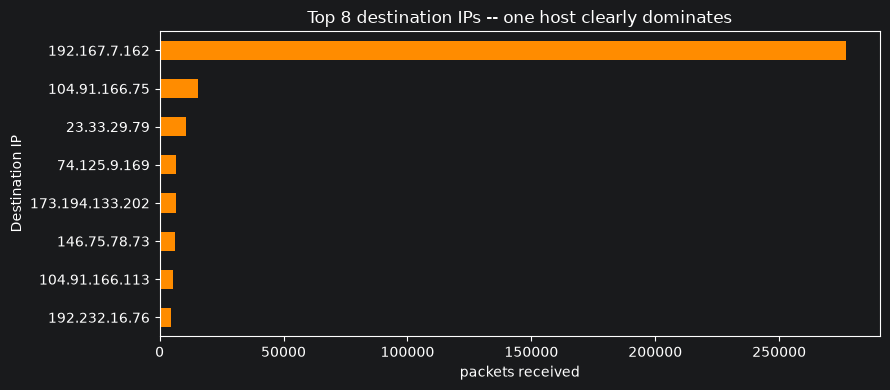

The single busiest destination receives 70.4% of all captured packets.


In [5]:
top_talkers = valid["Destination IP"].value_counts().head(8)
fig, ax = plt.subplots(figsize=(9, 4))
top_talkers.plot(kind="barh", ax=ax, color="darkorange")
ax.invert_yaxis()
ax.set_xlabel("packets received")
ax.set_title("Top 8 destination IPs -- one host clearly dominates")
plt.tight_layout()
plt.show()
dominant_share = top_talkers.iloc[0] / len(valid)
print(f"The single busiest destination receives {dominant_share:.1%} of all captured packets.")

## The topology-placement bug, visualized

That single dominant host is the whole reason topology-aware placement
mattered. If it lands on a low-degree node, no bandwidth policy can route
around a 2-link bottleneck.

The actual bug (now fixed) wasn't hashing itself -- plain hash bucketing
only *sometimes* lands the busiest node on a corner, by chance. The real
bug was assigning the most-frequent addresses **fixed, low node ids**
(`0, 1, 2, ...`) directly, on the assumption those were "safe" ids. They
weren't: NetworkX's grid labeling puts `0` at a corner. That mapping is
deterministic, so it deterministically broke every time. Reproducing it
exactly (rather than a random hash) is what makes this comparison honest:

node degrees: {0: 2, 1: 3, 2: 3, 3: 2, 4: 3, 5: 4, 6: 4, 7: 3, 8: 3, 9: 4, 10: 4, 11: 3, 12: 2, 13: 3, 14: 3, 15: 2}
node 0 (where the old code put the busiest address) has degree 2


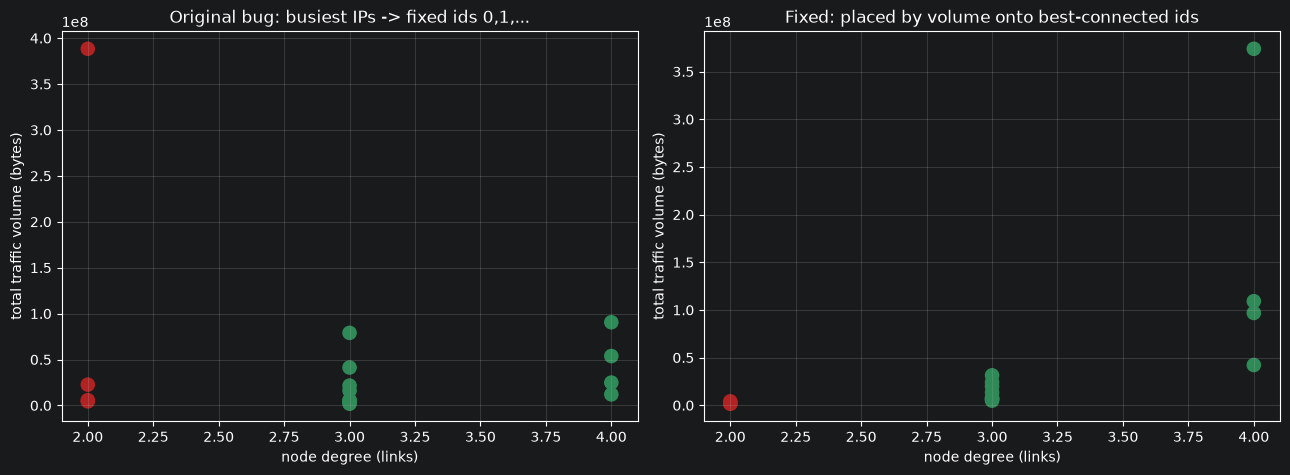

Busiest node's degree -- original bug: 2  |  fixed: 4


In [6]:
NUM_NODES = 16
net = NetworkModel(topology="grid", num_nodes=NUM_NODES)
degree = dict(net.graph.degree())
print("node degrees:", degree)
print(f"node 0 (where the old code put the busiest address) has degree {degree[0]}")

# naive (the ORIGINAL bug): the `dedicated` most-frequent IPs get fixed ids
# 0, 1, 2, ... directly; everything else hash-bucketed into the rest.
def naive_placement(col, dedicated=2):
    counts = valid[col].value_counts()
    top_map = {ip: i for i, ip in enumerate(counts.index[:dedicated])}
    remaining = NUM_NODES - dedicated
    return valid[col].apply(
        lambda ip: top_map[ip] if ip in top_map else dedicated + (hash(ip) % remaining)
    )

naive_src = naive_placement("Source IP")
naive_dst = naive_placement("Destination IP")
naive_load = (pd.Series(valid["Length"].values, index=naive_dst.values).groupby(level=0).sum()
             .add(pd.Series(valid["Length"].values, index=naive_src.values).groupby(level=0).sum(),
                  fill_value=0.0))

# fixed: the actual adapter, which places by volume onto the best-connected ids
fixed = convert_packet_capture("data/output1.csv", num_nodes=NUM_NODES, bin_seconds=5.0)
fixed_load = (fixed.groupby("dst")["volume"].sum()
             .add(fixed.groupby("src")["volume"].sum(), fill_value=0.0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, load, title in [(axes[0], naive_load, "Original bug: busiest IPs -> fixed ids 0,1,..."),
                        (axes[1], fixed_load, "Fixed: placed by volume onto best-connected ids")]:
    degs = [degree.get(n, 0) for n in load.index]
    vols = load.values
    colors = ["firebrick" if d <= 2 else "seagreen" for d in degs]
    ax.scatter(degs, vols, s=90, c=colors)
    ax.set_xlabel("node degree (links)")
    ax.set_ylabel("total traffic volume (bytes)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
busiest_naive_degree = degree[naive_load.idxmax()]
busiest_fixed_degree = degree[fixed_load.idxmax()]
print(f"Busiest node's degree -- original bug: {busiest_naive_degree}  |  fixed: {busiest_fixed_degree}")

## The converted trace: volume per step, ready for `TraceTrafficGenerator`

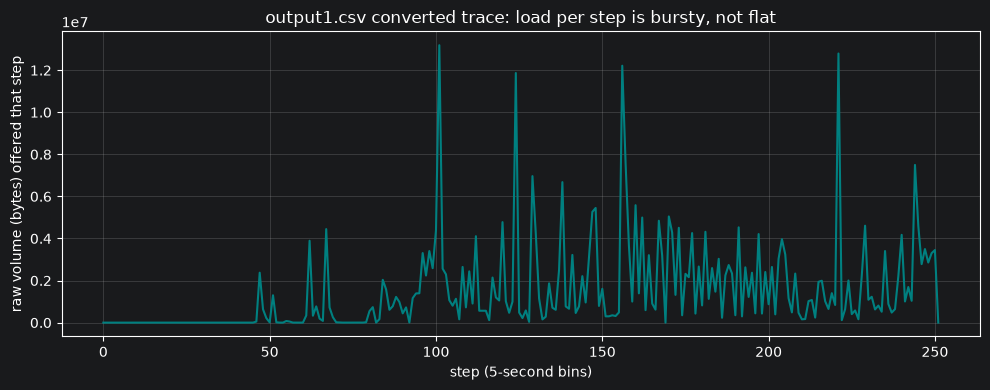

TraceTrafficGenerator(target_load=...) rescales this to whatever load you ask
for -- the raw units above don't matter, only the relative shape does.


In [7]:
per_step = fixed.groupby("step")["volume"].sum()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(per_step.index, per_step.values, color="teal")
ax.set_xlabel("step (5-second bins)")
ax.set_ylabel("raw volume (bytes) offered that step")
ax.set_title("output1.csv converted trace: load per step is bursty, not flat")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("TraceTrafficGenerator(target_load=...) rescales this to whatever load you ask")
print("for -- the raw units above don't matter, only the relative shape does.")